In [13]:
!pip -q install -U ultralytics gradio

In [15]:

import torch
from ultralytics import YOLO

device = 0 if torch.cuda.is_available() else "cpu"

print("학습 장치:", device)

# CNN 기반 이미지 분류 모델
model = YOLO("yolo26n-cls.pt")

# 학습
model.train(
    data="/content/skin_cls_dataset",
    epochs=20,
    imgsz=224,
    batch=16,
    device=device,
    workers=2,
    patience=7,
    plots=True,
    project="/content/skin_cls_runs",
    name="train",
    exist_ok=True
)

# 최고 성능 가중치 불러오기
best_model = YOLO(
    "/content/skin_cls_runs/train/weights/best.pt"
)

print("학습 완료!")
print("클래스:", best_model.names)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
학습 장치: 0
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/skin_cls_dataset, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1

In [16]:

metrics = best_model.val(
    data="/content/skin_cls_dataset",
    split="val",
    imgsz=224,
    device=device,
    plots=True
)

print("=" * 40)
print("YOLO 피부질환 분류 결과")
print("=" * 40)

print(f"Top-1 Accuracy: {metrics.top1 * 100:.2f}%")
print(f"Top-5 Accuracy: {metrics.top5 * 100:.2f}%")


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,545,239 parameters, 0 gradients, 3.2 GFLOPs
train: /content/skin_cls_dataset/train... found 12000 images in 15/15 classes ✅ 
val: /content/skin_cls_dataset/val... found 1500 images in 15/15 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3437.9±961.4 MB/s, size: 489.1 KB)
val: Scanning /content/skin_cls_dataset/val... 1500 images, 0 corrupt: 100% ━━━━━━━━━━━━ 1500/1500 393.2Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 94/94 5.7it/s 16.6s
                   all      0.999          1
Speed: 0.1ms preprocess, 1.1ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
YOLO 피부질환 분류 결과
Top-1 Accuracy: 99.93%
Top-5 Accuracy: 100.00%


Saving 피부병.png to 피부병.png

피부질환 분류 결과
사마귀: 71.87%
지루각화증: 21.12%
멜라닌세포모반: 2.87%


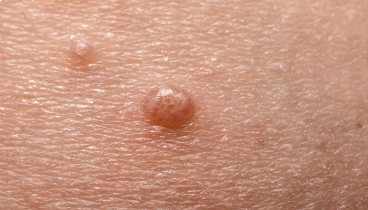

In [17]:

from google.colab import files
from PIL import Image
from IPython.display import display

uploaded = files.upload()

for filename in uploaded:

    result = best_model.predict(
        source=filename,
        imgsz=224,
        verbose=False
    )[0]

    print("\n피부질환 분류 결과")
    print("=" * 40)

    # 가능성이 높게 출력된 3개 클래스
    for idx in result.probs.top5[:3]:

        disease = result.names[idx]
        score = float(result.probs.data[idx])

        print(f"{disease}: {score * 100:.2f}%")

    display(Image.open(filename))


In [18]:

import gradio as gr

def predict_skin(image):

    if image is None:
        return {}

    result = best_model.predict(
        source=image,
        imgsz=224,
        verbose=False
    )[0]

    scores = result.probs.data.cpu().numpy()

    top3 = scores.argsort()[::-1][:3]

    return {
        result.names[int(i)]: float(scores[i])
        for i in top3
    }

demo = gr.Interface(
    fn=predict_skin,

    inputs=gr.Image(
        type="pil",
        label="피부 사진 업로드"
    ),

    outputs=gr.Label(
        num_top_classes=3,
        label="피부질환 분류 결과"
    ),

    title="AI 피부질환 분류 서비스",

    description=(
        "AI Hub 피부종양 합성 데이터로 학습한 "
        "15종 이미지 분류 모델입니다. "
        "의학적 진단을 대신하지 않습니다."
    )
)

demo.launch(share=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [19]:
import shutil

shutil.copy2(
    "/content/skin_cls_runs/train/weights/best.pt",
    "/content/drive/MyDrive/skindata/skin_cls_best.pt"
)

print("모델 저장 완료!")

모델 저장 완료!
